In [ ]:
from sklearn.model_selection import train_test_split
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

In [ ]:
df=pd.read_csv('PreprocessedData (7).csv', encoding='latin1')
df.head()

,Unnamed: 0,Type,Days for shipping (real),Days for shipment (scheduled),Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Item Quantity,Sales,Order Profit Per Order,Order Region,Order State,Order Status,Product Card Id,Product Name,shipping date (DateOrders),Shipping Mode
0,0,1,3,4,314.640015,0,0,73,40,65,...,1,327.75,91.250000,15,475,2,1360,78,3250,3
1,1,3,5,4,311.359985,1,1,73,40,65,...,1,327.75,-249.089996,13,841,5,1360,78,20134,3
2,2,0,4,4,309.720001,3,0,73,40,451,...,1,327.75,-247.779999,13,841,1,1360,78,19905,3
3,3,1,3,4,304.809998,0,0,73,40,284,...,1,327.75,22.860001,11,835,2,1360,78,19677,3
4,4,2,2,4,298.250000,0,0,73,40,65,...,1,327.75,134.210007,11,835,6,1360,78,19453,3


In [ ]:
df.columns

Index(['Unnamed: 0', 'Type', 'Days for shipping (real)',
       'Days for shipment (scheduled)', 'Sales per customer',
       'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name',
       'Customer City', 'Customer Country', 'Customer Segment',
       'Customer State', 'Customer Street', 'Customer Zipcode',
       'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market',
       'Order City', 'Order Country', 'Order Customer Id',
       'order date (DateOrders)', 'Order Item Discount',
       'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price',
       'Order Item Profit Ratio', 'Order Item Quantity', 'Sales',
       'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status',
       'Product Card Id', 'Product Name', 'shipping date (DateOrders)',
       'Shipping Mode'],
      dtype='object')

In [ ]:
abs(df.corr(numeric_only=True)['Late_delivery_risk']).sort_values(ascending=False)

,Late_delivery_risk
Late_delivery_risk,1.000000
Days for shipping (real),0.401428
Shipping Mode,0.401365
Days for shipment (scheduled),0.369342
Delivery Status,0.190489
Type,0.061528
Unnamed: 0,0.044917
Order Region,0.006153
Customer City,0.005075
Order Status,0.004125


In [ ]:
#choose relevant features based on the correlation values
selected_features = [
    'Days for shipping (real)',
    'Shipping Mode',
    'Days for shipment (scheduled)',
    'Delivery Status',
    'Type',
    'Order Region',
    'Customer City'
]

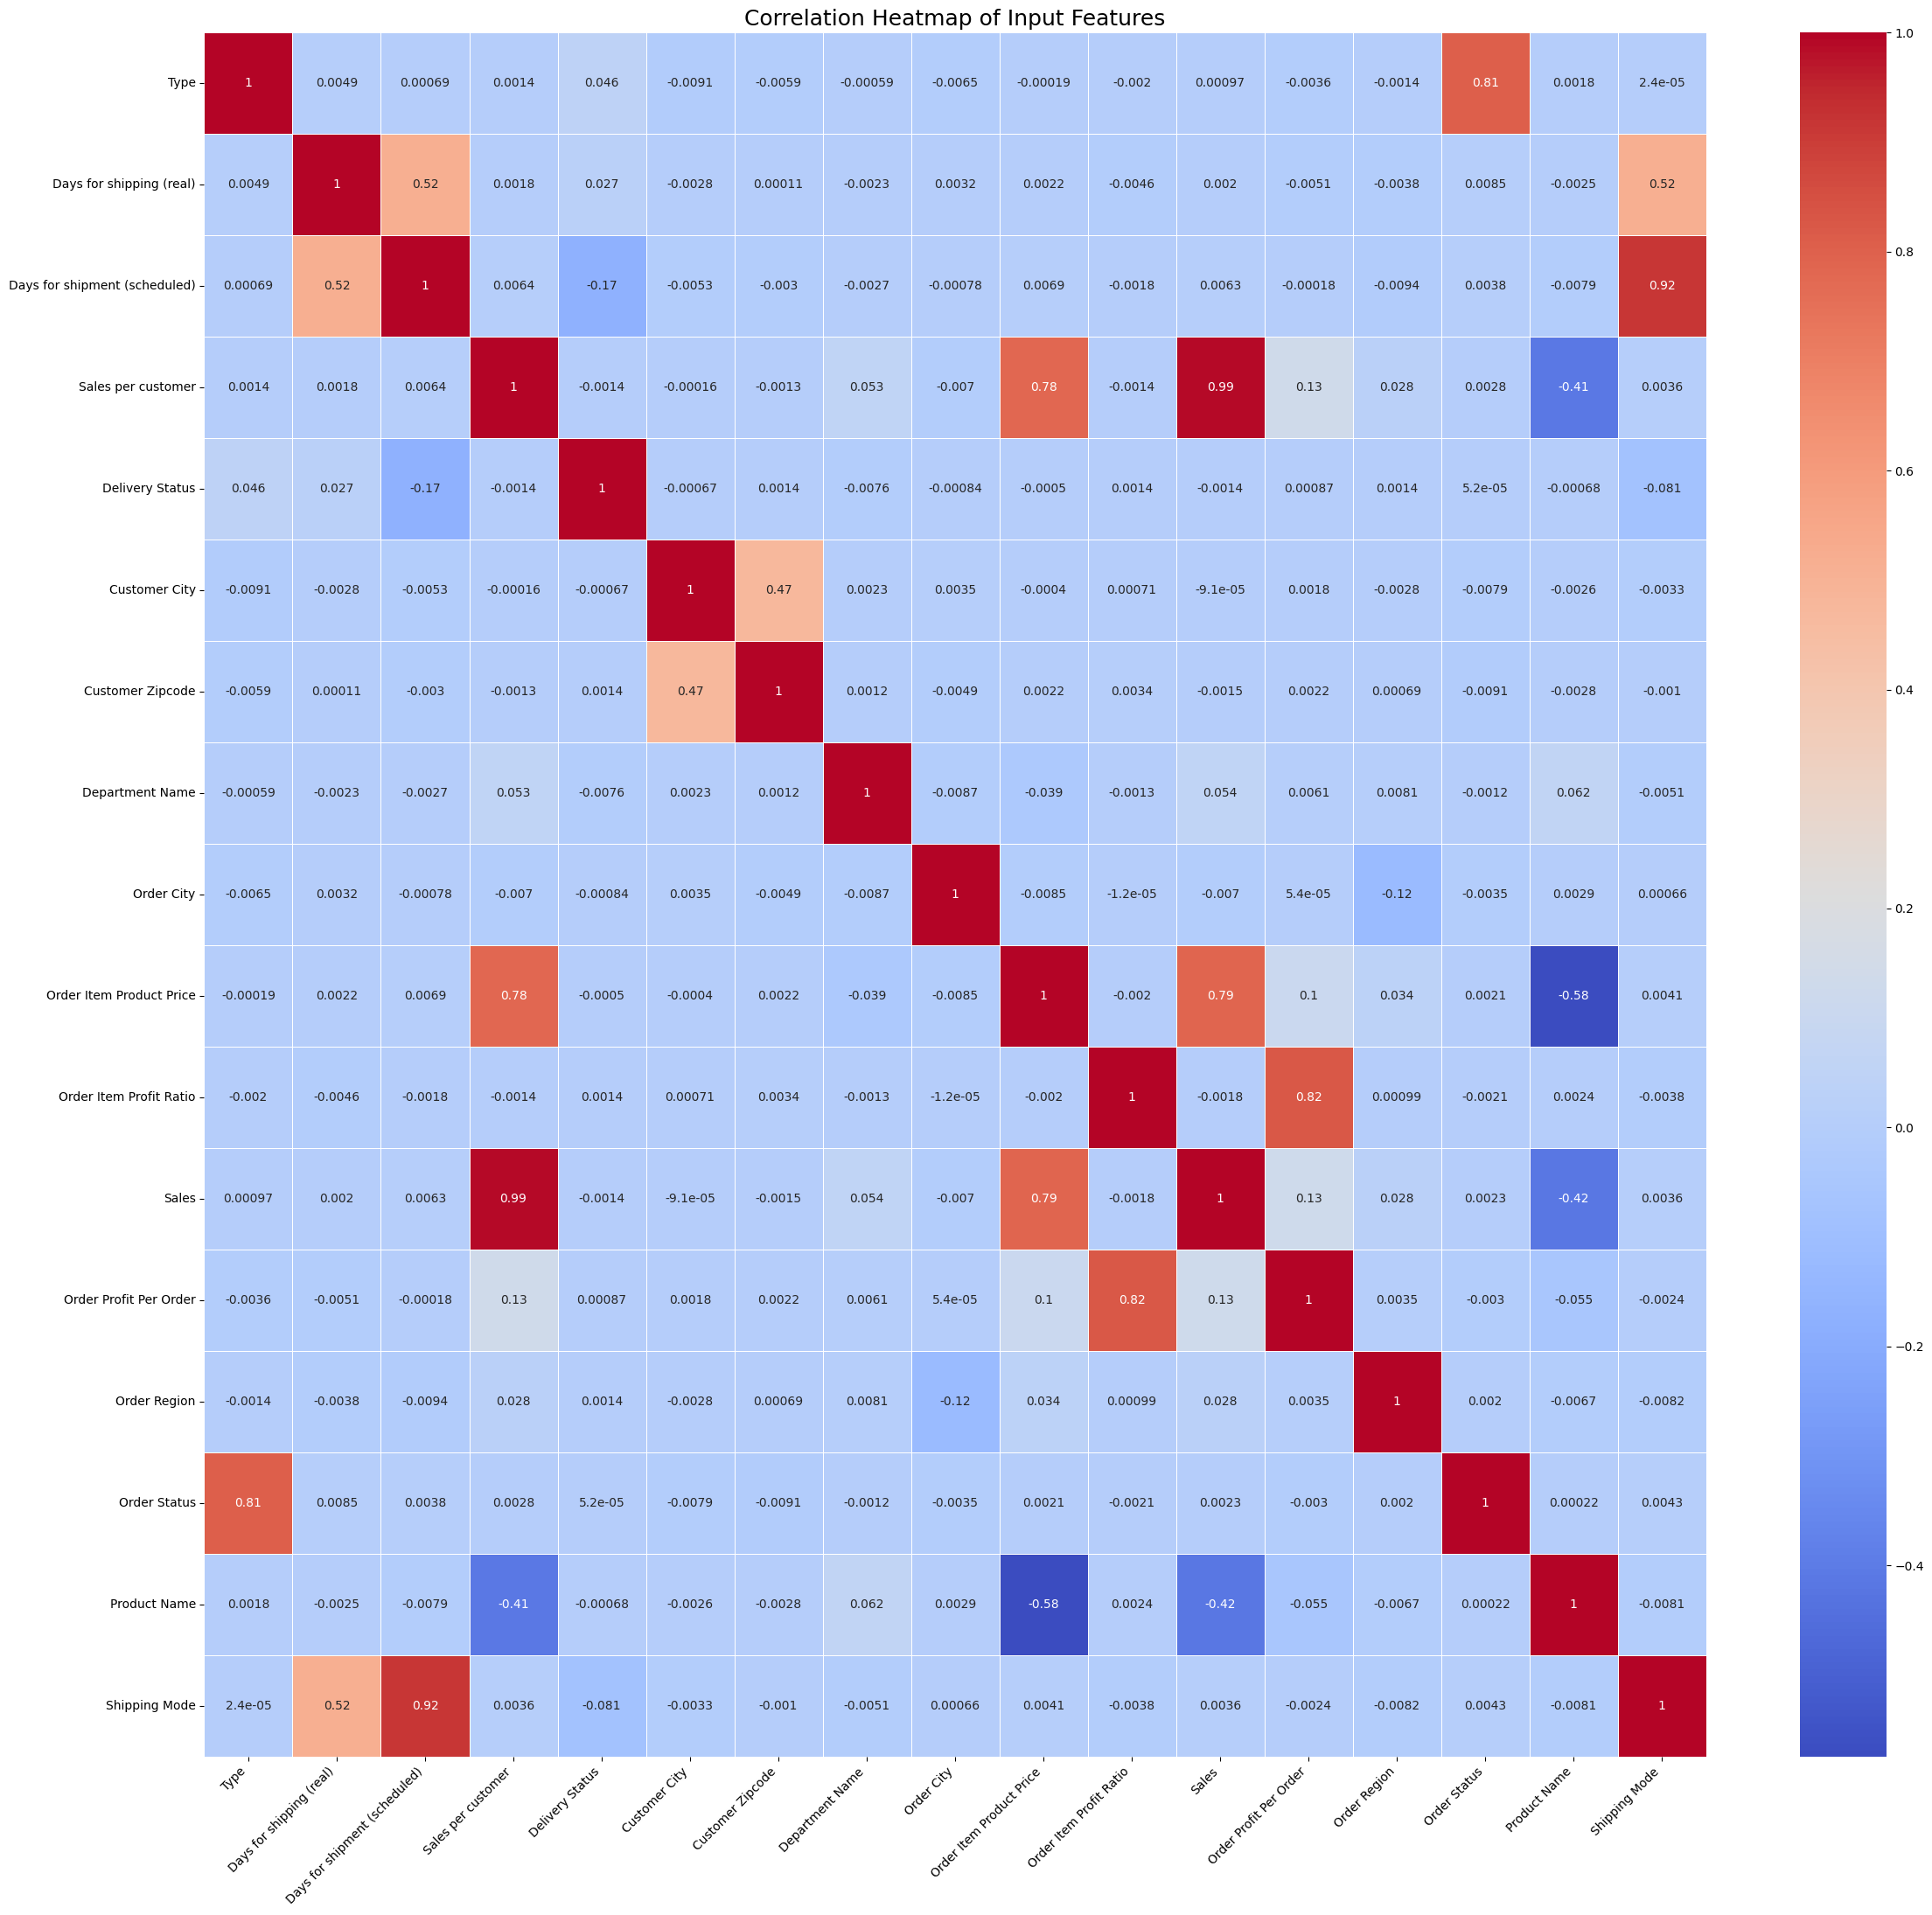

In [ ]:
y = df['Late_delivery_risk']
X = df.drop(columns=['Late_delivery_risk','Unnamed: 0','Longitude', 'Customer State',
'Category Id','Order Country','Product Card Id','Order Customer Id',
'shipping date (DateOrders)',
'Customer Segment',	'Order Item Id','Category Name','Order State','Department Id','Customer Country',
'Customer Street','Order Item Discount',
'Latitude','order date (DateOrders)',
'Market','Order Item Discount Rate','Order Item Quantity'])

corr_matrix = X.corr()

plt.figure(figsize=(24, 22))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap of Input Features', fontsize=18)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
#split data into training and testing data, 70% for training, 30% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3)

## Display the shapes for X_train:
print(f'\nX_train size is :{X_train.shape}')
## Display the shapes for X_test:
print(f'X_test size is :{X_test.shape}')
## Display the shapes for y_train:
print(f'y_train size is :{y_train.shape}')
## Display the shapes for y_test:
print(f'y_test size is :{y_test.shape}')


X_train size is :(126361, 17)
X_test size is :(54155, 17)
y_train size is :(126361,)
y_test size is :(54155,)


In [ ]:
#standardize values of features
scaler = StandardScaler()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3)
X_train_scaled = scaler.fit_transform(X_train)#train on and scale training data
X_test_scaled = scaler.transform(X_test)#scale testing data


In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

k=1 → Accuracy: 0.9953
k=2 → Accuracy: 0.9960
k=3 → Accuracy: 0.9945
k=4 → Accuracy: 0.9957
k=5 → Accuracy: 0.9939
k=6 → Accuracy: 0.9951
k=7 → Accuracy: 0.9933
k=8 → Accuracy: 0.9941
k=9 → Accuracy: 0.9925
k=10 → Accuracy: 0.9935
k=11 → Accuracy: 0.9918
k=12 → Accuracy: 0.9927
k=13 → Accuracy: 0.9911
k=14 → Accuracy: 0.9921
k=15 → Accuracy: 0.9905
k=16 → Accuracy: 0.9914

Best k: 2 with accuracy: 0.9960


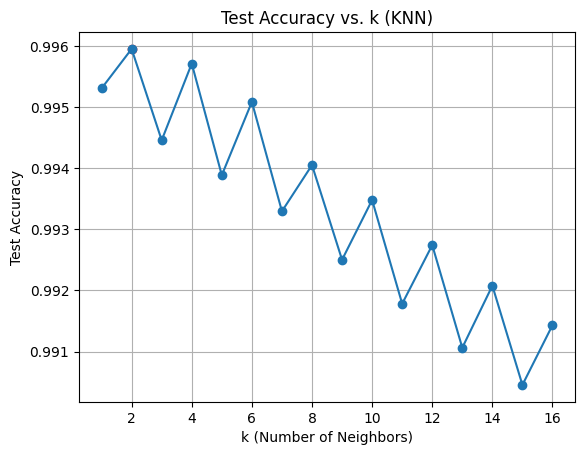

In [ ]:
# Store accuracy for each k
accuracy_scores = []

# Range of k to try
k_range = range(1, len(X_train.columns))

for k in k_range:
    ## Initialize KNN:
    knn = KNeighborsClassifier(n_neighbors=k)#try all k

    ## Train with scaled training features and training target
    knn.fit(X_train_scaled, y_train)

    ## Get the predicted values after training:
    y_pred = knn.predict(X_test_scaled)

    ## Find the accuracy score:
    acc = accuracy_score(y_test, y_pred)

    ## Add the accuracy score to the list
    accuracy_scores.append(acc)

    ## Display the obtained accuracy:
    print(f"k={k} → Accuracy: {acc:.4f}")


# Find the best k and display it
best_k = k_range[accuracy_scores.index(max(accuracy_scores))]
print(f"\nBest k: {best_k} with accuracy: {max(accuracy_scores):.4f}")

# 📊 Plot the results
plt.plot(list(k_range), accuracy_scores, marker='o')
plt.scatter(best_k, max(accuracy_scores), color='red', label=f'Best k = {best_k}')
plt.xlabel("k (Number of Neighbors)")
plt.ylabel("Test Accuracy")
plt.title("Test Accuracy vs. k (KNN)")
plt.grid(True)
plt.show()


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Train the final model with best k
best_knn = KNeighborsClassifier(n_neighbors=best_k)
best_knn.fit(X_train_scaled, y_train)

# Predict on training and test sets
train_preds = best_knn.predict(X_train_scaled)
test_preds = best_knn.predict(X_test_scaled)

# 📊 Evaluation on Training Data, to check if model actually learned
print("\n--- Evaluation on Training Data ---")
train_accuracy = accuracy_score(y_train, train_preds)
train_precision = precision_score(y_train, train_preds, average='binary')#we have binary targets 0 and 1
train_recall = recall_score(y_train, train_preds, average='binary')
train_f1 = f1_score(y_train, train_preds, average='binary')

print(f"Accuracy: {train_accuracy:.4f}")
print(f"Precision: {train_precision:.4f}")
print(f"Recall: {train_recall:.4f}")
print(f"F1-Score: {train_f1:.4f}")

# 📊 Evaluation on Test Data, to check the performance of the model on unseen data
print("\n--- Evaluation on Test Data ---")
test_accuracy = accuracy_score(y_test, test_preds)
test_precision = precision_score(y_test, test_preds, average='binary')
test_recall = recall_score(y_test, test_preds, average='binary')
test_f1 = f1_score(y_test, test_preds, average='binary')

print(f"Accuracy: {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall: {test_recall:.4f}")
print(f"F1-Score: {test_f1:.4f}")



--- Evaluation on Training Data ---
Accuracy: 0.9992
Precision: 1.0000
Recall: 0.9986
F1-Score: 0.9993

--- Evaluation on Test Data ---
Accuracy: 0.9960
Precision: 0.9957
Recall: 0.9970
F1-Score: 0.9963
